# Libraries Needed 

In [1]:
# Core Python
import os
import warnings
import gc

# Data handling
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Feature selection
from sklearn.feature_selection import SelectKBest, chi2, RFE

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

# Model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Outlier detection
from scipy.stats import zscore

# Oversampling
from imblearn.over_sampling import SMOTE

ModuleNotFoundError: No module named 'sklearn.utils._metadata_requests'

# Dataset Preview 

In [2]:
# Define paths
data_dir = "/kaggle/input/new-ph2"
X_train_file = "/kaggle/working/X_train.csv"
X_test_file = "/kaggle/working/X_test.csv"
y_train_file = "/kaggle/working/y_train.csv"
y_test_file = "/kaggle/working/y_test.csv"

# Define chunk size and required sample sizes
chunk_size = 50000
benign_samples_per_file = 300
attack_samples_per_file = 5000

# Clear old files if they exist
for file in [X_train_file, X_test_file, y_train_file, y_test_file]:
    if os.path.exists(file):
        os.remove(file)

print("Starting data processing...")

# Process each file
for file_name in os.listdir(data_dir):
    file_path = os.path.join(data_dir, file_name)
    print(f"Processing {file_name} in chunks...")

    benign_samples_list = []
    attack_samples_list = []
    benign_count = 0
    attack_count = 0

    for chunk in pd.read_csv(file_path, chunksize=chunk_size, dtype=str, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        if "Label" not in chunk.columns:
            continue

        chunk["Label"] = chunk["Label"].str.strip()

        # Extract benign and attack samples
        benign_mask = chunk["Label"] == "BENIGN"
        attack_mask = ~benign_mask

        benign_samples = chunk[benign_mask]
        attack_samples = chunk[attack_mask]

        # Add only the required number of benign samples
        if benign_count < benign_samples_per_file:
            needed = benign_samples_per_file - benign_count
            selected_benign = benign_samples.sample(n=min(needed, len(benign_samples)), random_state=42)
            benign_samples_list.append(selected_benign)
            benign_count += len(selected_benign)

        # Add only the required number of attack samples
        if attack_count < attack_samples_per_file:
            needed = attack_samples_per_file - attack_count
            selected_attack = attack_samples.sample(n=min(needed, len(attack_samples)), random_state=42)
            attack_samples_list.append(selected_attack)
            attack_count += len(selected_attack)

        # Stop processing if we have enough samples
        if benign_count >= benign_samples_per_file and attack_count >= attack_samples_per_file:
            break

    # Combine collected samples
    benign_final = pd.concat(benign_samples_list, ignore_index=True) if benign_samples_list else pd.DataFrame()
    attack_final = pd.concat(attack_samples_list, ignore_index=True) if attack_samples_list else pd.DataFrame()

    # Split into train/test 70/3(0)
    benign_train = benign_final.sample(frac=0.7, random_state=42)
    benign_test = benign_final.drop(benign_train.index)

    attack_train = attack_final.sample(frac=0.7, random_state=42)
    attack_test = attack_final.drop(attack_train.index)

    # Save to disk in append mode
    benign_train.drop(columns=["Label"]).to_csv(X_train_file, mode="a", index=False, header=not os.path.exists(X_train_file))
    benign_test.drop(columns=["Label"]).to_csv(X_test_file, mode="a", index=False, header=not os.path.exists(X_test_file))
    attack_train.drop(columns=["Label"]).to_csv(X_train_file, mode="a", index=False, header=False)
    attack_test.drop(columns=["Label"]).to_csv(X_test_file, mode="a", index=False, header=False)

    benign_train["Label"].to_csv(y_train_file, mode="a", index=False, header=not os.path.exists(y_train_file))
    benign_test["Label"].to_csv(y_test_file, mode="a", index=False, header=not os.path.exists(y_test_file))
    attack_train["Label"].to_csv(y_train_file, mode="a", index=False, header=False)
    attack_test["Label"].to_csv(y_test_file, mode="a", index=False, header=False)

    print(f"Processed {file_name} with {benign_count} benign and {attack_count} attack samples.")

    # Free up memory
    del benign_samples_list, attack_samples_list, benign_final, attack_final, benign_train, benign_test, attack_train, attack_test
    gc.collect()

# Load final dataset for confirmation
print("\nFinal dataset sizes:")
dtype_options = {col: "str" for col in range(85)}  # Force all columns to string
X_train = pd.read_csv(X_train_file, dtype=dtype_options, low_memory=False)
X_test = pd.read_csv(X_test_file, dtype=dtype_options, low_memory=False)
y_train = pd.read_csv(y_train_file, dtype=str, low_memory=False)
y_test = pd.read_csv(y_test_file, dtype=str, low_memory=False)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


Starting data processing...
Processing DrDoS_NetBIOS.csv in chunks...
Processed DrDoS_NetBIOS.csv with 300 benign and 5000 attack samples.
Processing DrDoS_SSDP.csv in chunks...
Processed DrDoS_SSDP.csv with 300 benign and 5000 attack samples.
Processing DrDoS_NTP.csv in chunks...
Processed DrDoS_NTP.csv with 300 benign and 5000 attack samples.
Processing DrDoS_UDP.csv in chunks...
Processed DrDoS_UDP.csv with 300 benign and 5000 attack samples.
Processing DrDoS_MSSQL.csv in chunks...
Processed DrDoS_MSSQL.csv with 300 benign and 5000 attack samples.
Processing DrDoS_SNMP.csv in chunks...
Processed DrDoS_SNMP.csv with 300 benign and 5000 attack samples.
Processing DrDoS_DNS.csv in chunks...
Processed DrDoS_DNS.csv with 300 benign and 5000 attack samples.
Processing DrDoS_LDAP.csv in chunks...
Processed DrDoS_LDAP.csv with 300 benign and 5000 attack samples.

Final dataset sizes:
X_train shape: (29680, 87)
X_test shape: (12720, 87)
y_train shape: (29680, 1)
y_test shape: (12720, 1)


In [3]:
# Load split datasets
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")
y_test = pd.read_csv("y_test.csv")

# Flatten y arrays in case they're 2D
y_train = y_train.squeeze()
y_test = y_test.squeeze()

# Append label column to the feature sets
X_train_full = X_train.copy()
X_train_full["Label"] = y_train

X_test_full = X_test.copy()
X_test_full["Label"] = y_test

# Save full combined versions
X_train_full.to_csv("X_train_full_with_label.csv", index=False)
X_test_full.to_csv("X_test_full_with_label.csv", index=False)

print("Files saved: X_train_full_with_label.csv and X_test_full_with_label.csv")


Files saved: X_train_full_with_label.csv and X_test_full_with_label.csv


# Null Values & Outliers  

In [4]:
# Handling Null and Infinite Values for X_train and X_test
for dataset_name, dataset in [("X_train", X_train), ("X_test", X_test)]:
    for col in dataset.columns:
        if pd.api.types.is_numeric_dtype(dataset[col]):  # Process only numeric columns
            # Ensure infinity values are replaced with NaN properly
            dataset[col] = dataset[col].replace([np.inf, -np.inf], np.nan)
            
            null_count = dataset[col].isnull().sum()
            if null_count > 0:
                print(f"\nProcessing {dataset_name} - Column: {col}")
                print(f"  Null Values: {null_count} ({round((null_count / len(dataset)) * 100, 3)}%)")

# Drop extreme values beyond float64 limits 
for dataset_name, dataset in [("X_train", X_train), ("X_test", X_test)]:
    for col in dataset.columns:
        if pd.api.types.is_numeric_dtype(dataset[col]):
            dataset[col] = dataset[col].clip(-1e10, 1e10)  # Clipping extreme large values

# Impute missing values with the median **after all replacements**
imputer = SimpleImputer(strategy="median")
for dataset_name, dataset in [("X_train", X_train), ("X_test", X_test)]:
    for col in dataset.columns:
        if pd.api.types.is_numeric_dtype(dataset[col]):  
            dataset[col] = imputer.fit_transform(dataset[[col]])

X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
X_train.fillna(0, inplace=True)
X_test.fillna(0, inplace=True)

def find_outliers_zscore(df, threshold=3):
    outliers = pd.DataFrame()

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            clean_col = df[col].replace([np.inf, -np.inf], np.nan).dropna()

            if clean_col.nunique() > 1:  # Avoid zero std dev
                z_scores = zscore(clean_col)

                # Only use valid (non-NaN) z-score values
                valid_indices = clean_col.index[np.abs(z_scores) > threshold].tolist()
                col_outliers = df.loc[valid_indices]

                outliers = pd.concat([outliers, col_outliers])

    return outliers.drop_duplicates()


# Identify outliers separately for X_train and X_test
outliers_train = find_outliers_zscore(X_train)
outliers_test = find_outliers_zscore(X_test)

print(f"Found {len(outliers_train)} outliers in X_train.")
print(f"Found {len(outliers_test)} outliers in X_test.")



Processing X_train - Column: Flow Bytes/s
  Null Values: 626 (2.109%)

Processing X_train - Column: Flow Packets/s
  Null Values: 626 (2.109%)

Processing X_test - Column: Flow Bytes/s
  Null Values: 262 (2.06%)

Processing X_test - Column: Flow Packets/s
  Null Values: 262 (2.06%)


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/co

Found 5343 outliers in X_train.
Found 2233 outliers in X_test.


# Encoding 

In [5]:
# Define unwanted columns to drop
unwanted_columns = ['Flow ID', 'Source IP', 'Destination IP', 'Source Port', 'Destination Port', 'Timestamp']

# Load datasets
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")
y_test = pd.read_csv("y_test.csv")

# Drop unwanted columns if they exist
X_train = X_train.drop(columns=[col for col in unwanted_columns if col in X_train.columns], errors='ignore')
X_test = X_test.drop(columns=[col for col in unwanted_columns if col in X_test.columns], errors='ignore')

# Ensure y_train and y_test are numeric before encoding
if not pd.api.types.is_numeric_dtype(y_train):
    y_train = y_train.astype(str).values.ravel()
    y_test = y_test.astype(str).values.ravel()

# Encode target labels
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

# Save label mapping
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Label Encoding Mapping:", label_mapping)

# Encode categorical features in X_train and X_test if they are not numeric
categorical_columns = X_train.select_dtypes(include=['object']).columns

for col in categorical_columns:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))

    # Handle unseen values in X_test
    unseen_mask = ~X_test[col].isin(le.classes_)
    le.classes_ = np.append(le.classes_, 'unknown')

    # Replace unseen values in X_test with 'unknown' category
    X_test[col] = X_test[col].apply(lambda x: x if x in le.classes_ else 'unknown')
    X_test[col] = le.transform(X_test[col])

print("X_train and X_test encoded successfully.")


Label Encoding Mapping: {'BENIGN': 0, 'DrDoS_DNS': 1, 'DrDoS_LDAP': 2, 'DrDoS_MSSQL': 3, 'DrDoS_NTP': 4, 'DrDoS_NetBIOS': 5, 'DrDoS_SNMP': 6, 'DrDoS_SSDP': 7, 'DrDoS_UDP': 8}
X_train and X_test encoded successfully.


# Class Distruibution 

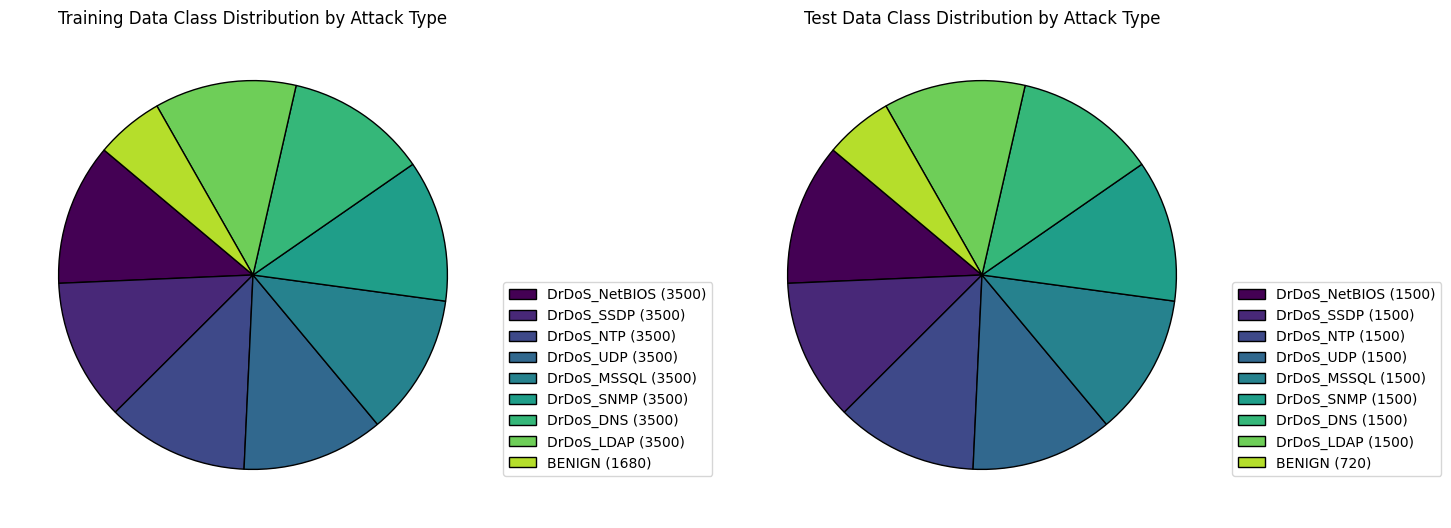

In [6]:
def plot_class_distribution(y_train, y_test, label_mapping):
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    colormap = plt.get_cmap("viridis")

    # Convert encoded labels back to original class names
    y_train_named = pd.Series([label_mapping.get(label, "Unknown") for label in y_train])
    y_test_named = pd.Series([label_mapping.get(label, "Unknown") for label in y_test])

    # Training set distribution
    train_counts = y_train_named.value_counts()
    train_labels = [f"{label} ({count})" for label, count in zip(train_counts.index, train_counts.values)]

    # Test set distribution
    test_counts = y_test_named.value_counts()
    test_labels = [f"{label} ({count})" for label, count in zip(test_counts.index, test_counts.values)]

    # Pie Chart for Training Data
    train_wedges, _ = axes[0].pie(
        train_counts, labels=None, startangle=140,
        colors=[colormap(i / len(train_counts)) for i in range(len(train_counts))],
        wedgeprops={'edgecolor': 'black'}
    )
    axes[0].set_title("Training Data Class Distribution by Attack Type")
    axes[0].legend(train_wedges, train_labels, loc="best", bbox_to_anchor=(1, 0.5))

    test_wedges, _ = axes[1].pie(
        test_counts, labels=None, startangle=140,
        colors=[colormap(i / len(test_counts)) for i in range(len(test_counts))],
        wedgeprops={'edgecolor': 'black'}
    )
    axes[1].set_title("Test Data Class Distribution by Attack Type")
    axes[1].legend(test_wedges, test_labels, loc="best", bbox_to_anchor=(1, 0.5))

    plt.subplots_adjust(right=0.8, wspace=0.5)
    plt.show()

label_mapping = {
    0: "BENIGN",
    1: "DrDoS_DNS",
    2: "DrDoS_LDAP",
    3: "DrDoS_MSSQL",
    4: "DrDoS_NTP",
    5: "DrDoS_NetBIOS",
    6: "DrDoS_SNMP",
    7: "DrDoS_SSDP",
    8: "DrDoS_UDP"
}

plot_class_distribution(y_train, y_test, label_mapping)


## Scaling

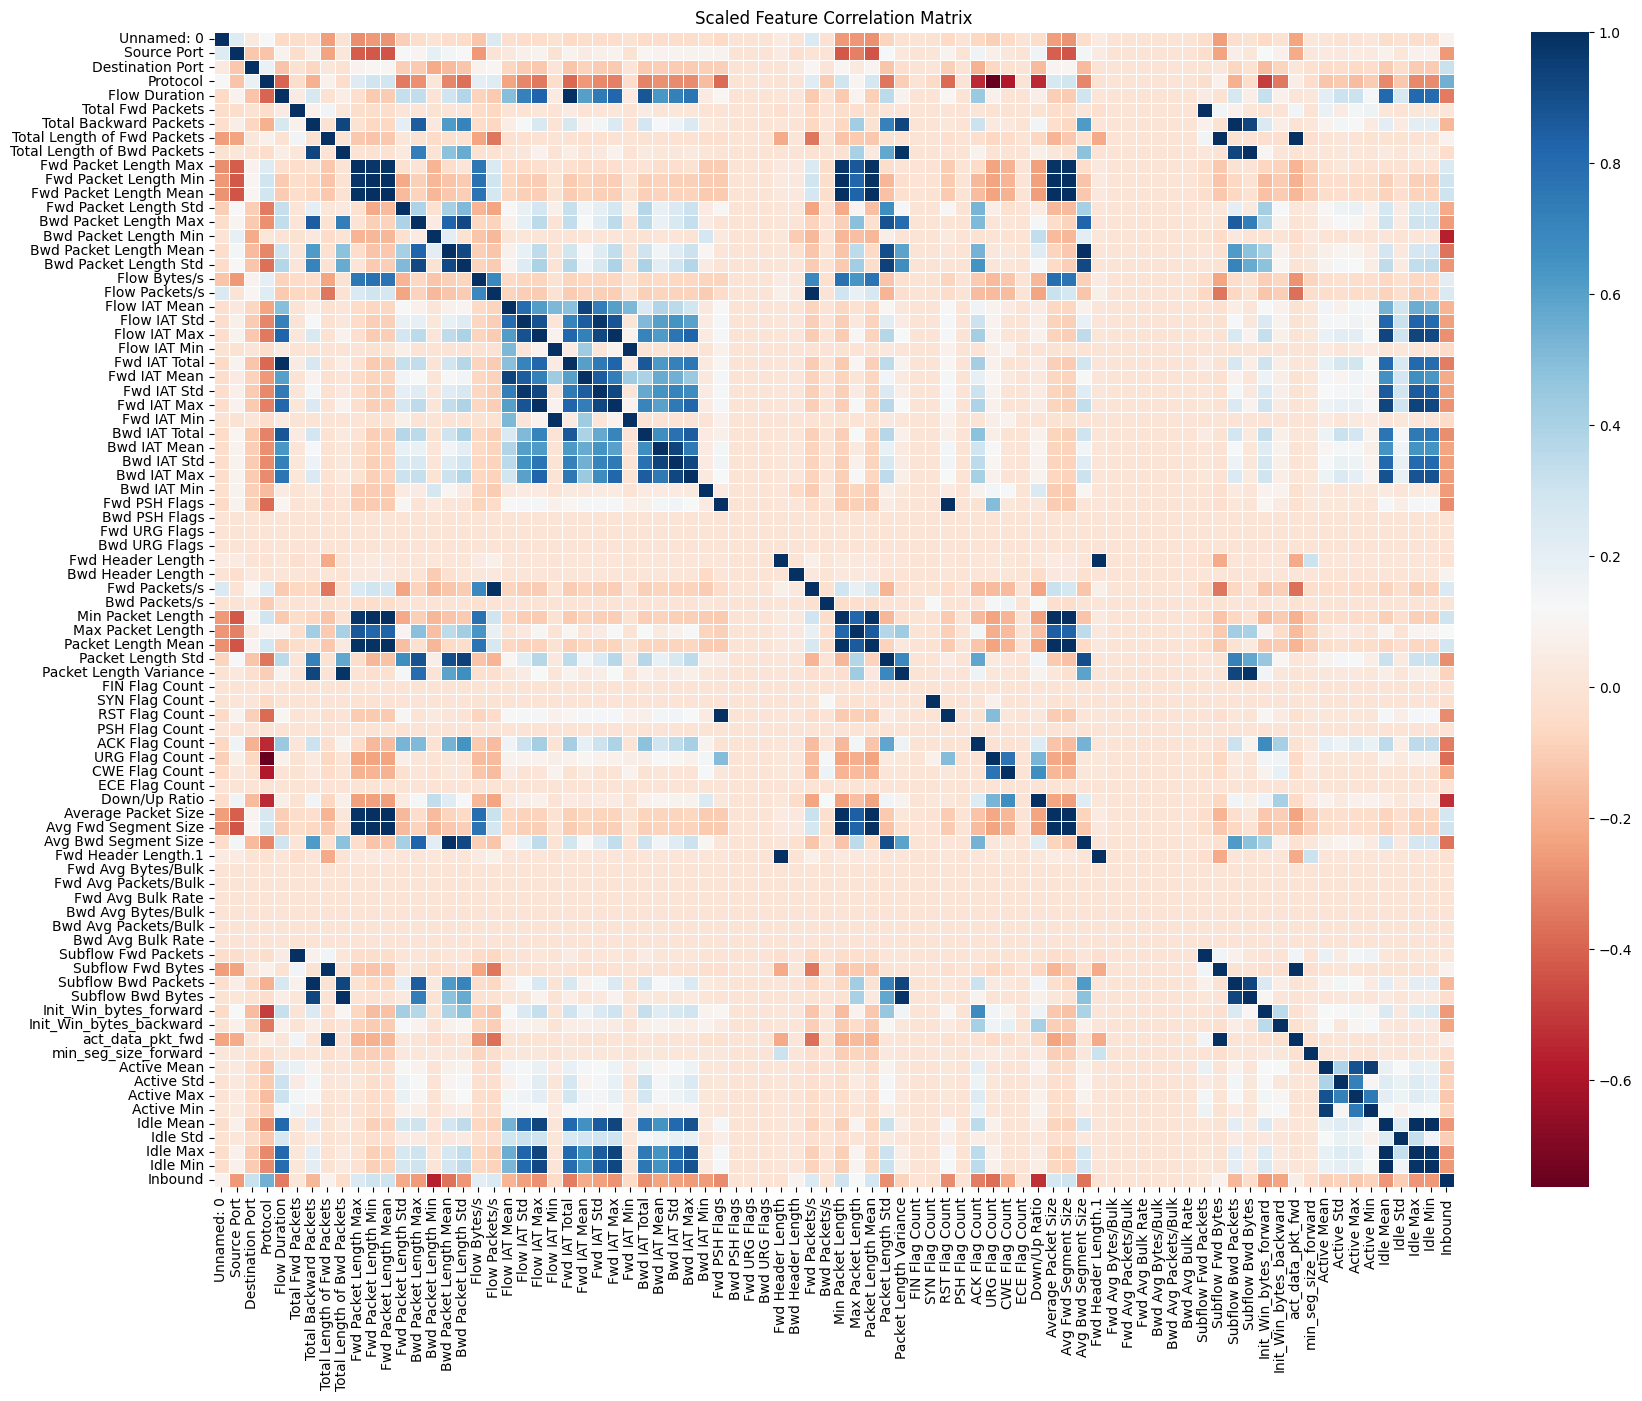

Scaled X_train shape: (29680, 82)
Scaled X_test shape: (12720, 82)

Scaled X_train Head:
   Unnamed: 0  Source Port  Destination Port  Protocol  Flow Duration  \
0   -0.812631     1.586609         -1.544850 -4.351563      -0.080313   
1    3.295271    -0.766899         -1.563648  0.221068       5.367846   
2    0.007045     1.555360         -1.564348  0.221068      -0.083848   
3   -0.812885     1.586490         -1.544850 -4.351563      -0.089497   
4   -0.301484    -0.752066          1.408312 -4.351563      -0.089477   

   Total Fwd Packets  Total Backward Packets  Total Length of Fwd Packets  \
0          -0.024270                0.846800                    -0.139087   
1          -0.034878               -0.050468                    -0.274015   
2          -0.052557                0.173849                    -0.382626   
3          -0.052557               -0.050468                    -0.385592   
4          -0.056092                0.173849                    -0.387263   

   Total 

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

try:
    X_train = pd.read_csv("X_train.csv")
    X_test = pd.read_csv("X_test.csv")
except FileNotFoundError as e:
    print(f"Error: {e}")
    raise SystemExit("Ensure all required dataset files exist before running the script.")

non_numeric_cols = X_train.select_dtypes(include=['object']).columns
X_train_numeric = X_train.drop(columns=non_numeric_cols, errors='ignore')
X_test_numeric = X_test.drop(columns=non_numeric_cols, errors='ignore')

X_train_numeric = X_train_numeric.apply(pd.to_numeric, errors='coerce')
X_test_numeric = X_test_numeric.apply(pd.to_numeric, errors='coerce')

# Replace NaN or infinity with 0
X_train_numeric.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test_numeric.replace([np.inf, -np.inf], np.nan, inplace=True)
X_train_numeric.fillna(0, inplace=True)
X_test_numeric.fillna(0, inplace=True)

# Ensure there are still valid features to scale
if X_train_numeric.shape[1] > 0:
    
    scaler = StandardScaler()

    # Scale the data
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_numeric), columns=X_train_numeric.columns)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test_numeric), columns=X_test_numeric.columns)

    # Compute correlation matrix
    correlation_matrix = X_train_scaled.corr().fillna(0)

    plt.figure(figsize=(20, 15))
    sns.heatmap(correlation_matrix, annot=False, cmap='RdBu', linewidths=0.5)

    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.title("Scaled Feature Correlation Matrix")
    plt.show()

    print(f"Scaled X_train shape: {X_train_scaled.shape}")
    print(f"Scaled X_test shape: {X_test_scaled.shape}")
    print("\nScaled X_train Head:")
    print(X_train_scaled.head())
    print("\nScaled X_test Head:")
    print(X_test_scaled.head())

else:
    print("No numeric columns available for scaling.")


In [8]:
# Rename for consistent use in feature selection and models
X_train = X_train_scaled
X_test = X_test_scaled


## FEATURE ELIMINATION

In [10]:
# Initialize storage
model_results = []

In [60]:
# Save full data first (do this once before any FS)
X_train_full = X_train.copy()
X_test_full = X_test.copy()


In [12]:
# Use no feature selelction first 

"""feature_selection_name = "None" """


In [29]:
"""from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Copy original data
X_train = X_train_full.copy()
X_test = X_test_full.copy()

# Base model
lr = LogisticRegression(max_iter=1000, solver='liblinear')

feature_selection_name = "RFE"

# Select top k features
rfe = RFE(estimator=lr, n_features_to_select=40, step = 5)
rfe.fit(X_train, y_train)

# Get selected features
selected_columns = X_train.columns[rfe.support_]
X_train = X_train[selected_columns]
X_test = X_test[selected_columns]

print("RFE selected features:", list(selected_columns))
"""

RFE selected features: ['Unnamed: 0', 'Source Port', 'Protocol', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Mean', 'Bwd IAT Max', 'Fwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Subflow Fwd Bytes', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Idle Mean', 'Idle Max', 'Idle Min', 'Inbound']


In [45]:
"""
# Copy original data
X_train = X_train_full.copy()
X_test = X_test_full.copy()

feature_selection_name = "Random Forest FS"

# Fit random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Get top k important features
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:40]
selected_columns = X_train.columns[indices]

X_train = X_train[selected_columns]
X_test = X_test[selected_columns]

print("Random Forest selected features:", list(selected_columns))
"""

Random Forest selected features: ['Source Port', 'Unnamed: 0', 'Fwd Packet Length Max', 'Subflow Fwd Bytes', 'Avg Fwd Segment Size', 'Max Packet Length', 'Average Packet Size', 'Total Length of Fwd Packets', 'Fwd Packet Length Mean', 'Fwd Packet Length Min', 'Min Packet Length', 'Packet Length Mean', 'Flow Bytes/s', 'act_data_pkt_fwd', 'Flow IAT Max', 'Flow IAT Mean', 'Flow IAT Min', 'min_seg_size_forward', 'Fwd Packets/s', 'Fwd IAT Max', 'Fwd IAT Min', 'Flow IAT Std', 'Fwd IAT Std', 'Fwd IAT Mean', 'Inbound', 'Packet Length Variance', 'Packet Length Std', 'Fwd Packet Length Std', 'Protocol', 'Bwd IAT Max', 'Bwd IAT Mean', 'Bwd Packet Length Max', 'URG Flag Count', 'CWE Flag Count', 'Idle Max', 'Idle Min', 'Bwd Packet Length Std', 'ACK Flag Count', 'Bwd Packet Length Min', 'Idle Mean']


In [61]:
"""from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

# Copy original data
X_train = X_train_full.copy()
X_test = X_test_full.copy()

feature_selection_name = "Chi-Square"

# Scale features for chi2
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply chi2
chi2_selector = SelectKBest(score_func=chi2, k=40)
chi2_selector.fit(X_train_scaled, y_train)

selected_columns = X_train.columns[chi2_selector.get_support()]
X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns)[selected_columns]
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns)[selected_columns]

print("Chi2 selected features:", list(selected_columns))
"""

Chi2 selected features: ['Source Port', 'Unnamed: 0', 'Fwd Packet Length Max', 'Subflow Fwd Bytes', 'Avg Fwd Segment Size', 'Max Packet Length', 'Average Packet Size', 'Total Length of Fwd Packets', 'Fwd Packet Length Mean', 'Fwd Packet Length Min', 'Min Packet Length', 'Packet Length Mean', 'Flow Bytes/s', 'act_data_pkt_fwd', 'Flow IAT Max', 'Flow IAT Mean', 'Flow IAT Min', 'min_seg_size_forward', 'Fwd Packets/s', 'Fwd IAT Max', 'Fwd IAT Min', 'Flow IAT Std', 'Fwd IAT Std', 'Fwd IAT Mean', 'Inbound', 'Packet Length Variance', 'Packet Length Std', 'Fwd Packet Length Std', 'Protocol', 'Bwd IAT Max', 'Bwd IAT Mean', 'Bwd Packet Length Max', 'URG Flag Count', 'CWE Flag Count', 'Idle Max', 'Idle Min', 'Bwd Packet Length Std', 'ACK Flag Count', 'Bwd Packet Length Min', 'Idle Mean']


# OLD ALGORITHMS

## KNN Classifier


=== KNN ===
Accuracy: 0.8648584905660377

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       720
           1       0.78      0.85      0.81      1500
           2       0.73      0.81      0.77      1500
           3       0.79      0.70      0.75      1500
           4       0.97      0.97      0.97      1500
           5       0.96      0.88      0.92      1500
           6       0.99      1.00      1.00      1500
           7       0.78      0.68      0.73      1500
           8       0.86      0.96      0.91      1500

    accuracy                           0.86     12720
   macro avg       0.87      0.87      0.87     12720
weighted avg       0.87      0.86      0.86     12720



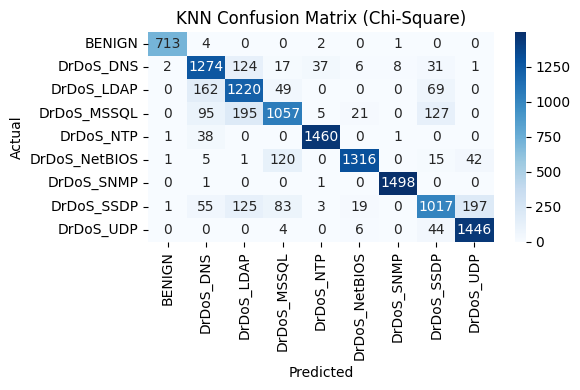

In [62]:
# =============== KNN ===============
knn = KNeighborsClassifier()
knn.fit(X_train, y_train.copy())
y_pred = knn.predict(X_test)

model_name = "KNN" 

accuracy = accuracy_score(y_test, y_pred)


report = classification_report(y_test, y_pred, output_dict=True)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})
        
print("\n=== KNN ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Classification Report:\n", classification_report(y_test, y_pred))

model_name = "KNN"  # change per model

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


## Decision Tree

=== Decision Tree ===
Accuracy: 0.8789308176100629

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99       720
           1       0.88      0.88      0.88      1500
           2       0.80      0.78      0.79      1500
           3       0.74      0.73      0.73      1500
           4       0.98      0.98      0.98      1500
           5       0.95      0.96      0.96      1500
           6       1.00      1.00      1.00      1500
           7       0.73      0.76      0.74      1500
           8       0.91      0.90      0.90      1500

    accuracy                           0.88     12720
   macro avg       0.89      0.89      0.89     12720
weighted avg       0.88      0.88      0.88     12720



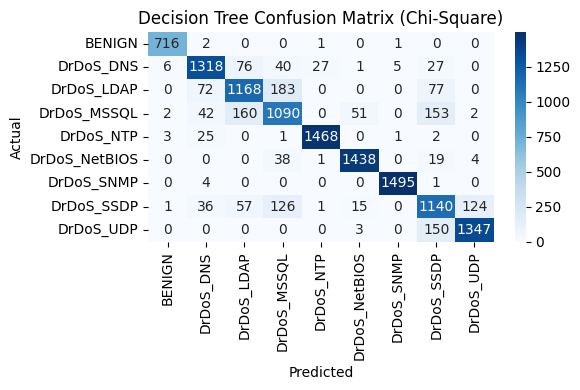

In [63]:
# =============== DECISION TREE ===============
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train.copy())
y_pred = dt.predict(X_test)

model_name = "Decision Tree"  

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})
        
print("=== Decision Tree ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Classification Report:\n", classification_report(y_test, y_pred))

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [64]:
"""from sklearn import tree

# ========== Decision Tree Visualization ==========
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train.copy(), y_train.copy())

plt.figure(figsize=(20,10))
tree.plot_tree(dt_model, feature_names=X_train.columns, class_names=True, filled=True)
plt.title("Decision Tree Visualization")
plt.show()"""

'from sklearn import tree\n\n# ========== Decision Tree Visualization ==========\ndt_model = DecisionTreeClassifier()\ndt_model.fit(X_train.copy(), y_train.copy())\n\nplt.figure(figsize=(20,10))\ntree.plot_tree(dt_model, feature_names=X_train.columns, class_names=True, filled=True)\nplt.title("Decision Tree Visualization")\nplt.show()'

## Random Forest Classifier 


=== Random Forest ===
Accuracy: 0.894811320754717

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       720
           1       0.90      0.87      0.89      1500
           2       0.78      0.81      0.79      1500
           3       0.79      0.72      0.75      1500
           4       0.98      0.99      0.98      1500
           5       0.96      0.95      0.95      1500
           6       1.00      1.00      1.00      1500
           7       0.80      0.80      0.80      1500
           8       0.90      0.98      0.94      1500

    accuracy                           0.89     12720
   macro avg       0.90      0.90      0.90     12720
weighted avg       0.89      0.89      0.89     12720



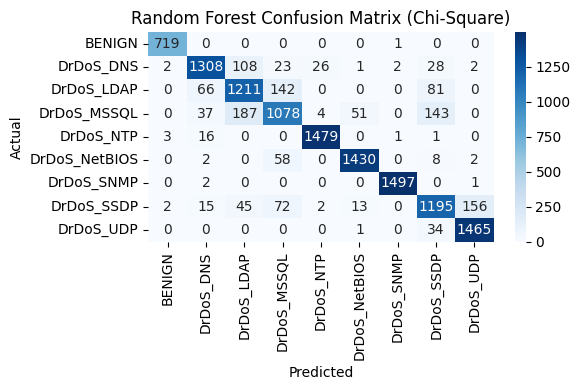

In [65]:
# =============== RANDOM FOREST ===============
rf = RandomForestClassifier()
rf.fit(X_train, y_train.copy())
y_pred = rf.predict(X_test)

model_name = "Random Forest" 

report = classification_report(y_test, y_pred, output_dict=True)

accuracy = accuracy_score(y_test, y_pred)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})

print("\n=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Classification Report:\n", classification_report(y_test, y_pred))

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [66]:
""""# ========== Random Forest (1st Tree Only) ==========
rf_model = RandomForestClassifier()
rf_model.fit(X_train.copy(), y_train.copy())

plt.figure(figsize=(20,10))
tree.plot_tree(rf_model.estimators_[0], feature_names=X_train.columns, class_names=True, filled=True)
plt.title("First Tree from Random Forest")
plt.show()"""

'"# ========== Random Forest (1st Tree Only) ==========\nrf_model = RandomForestClassifier()\nrf_model.fit(X_train.copy(), y_train.copy())\n\nplt.figure(figsize=(20,10))\ntree.plot_tree(rf_model.estimators_[0], feature_names=X_train.columns, class_names=True, filled=True)\nplt.title("First Tree from Random Forest")\nplt.show()'

## Logisitic Regression Classifier


=== Logistic Regression ===
Accuracy: 0.7066037735849057

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.93      0.90       720
           1       0.45      0.30      0.36      1500
           2       0.50      0.76      0.60      1500
           3       0.65      0.41      0.50      1500
           4       0.83      0.87      0.85      1500
           5       0.86      0.78      0.82      1500
           6       0.94      0.99      0.96      1500
           7       0.57      0.50      0.53      1500
           8       0.74      0.95      0.83      1500

    accuracy                           0.71     12720
   macro avg       0.71      0.72      0.71     12720
weighted avg       0.70      0.71      0.69     12720



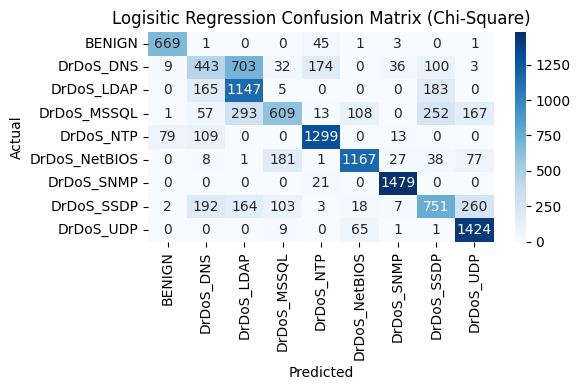

In [67]:
from sklearn.linear_model import LogisticRegression

# =============== LOGISTIC REGRESSION ===============
lr = LogisticRegression(multi_class='multinomial', max_iter=1000)
lr.fit(X_train, y_train.copy())
y_pred = lr.predict(X_test)

model_name = "Logisitic Regression"  # change per model
accuracy = accuracy_score(y_test, y_pred)

report = classification_report(y_test, y_pred, output_dict=True)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})

print("\n=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Classification Report:\n", classification_report(y_test, y_pred))


# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# NEW ALGORITHMS 

## Random Forest Classifier w/ Co-Training 


=== RF + Co-Training ===
Accuracy: 0.8949685534591195
              precision    recall  f1-score       support
0              0.988996  0.998611  0.993780    720.000000
1              0.905817  0.872000  0.888587   1500.000000
2              0.775367  0.810000  0.792305   1500.000000
3              0.796460  0.720000  0.756303   1500.000000
4              0.977543  0.986667  0.982084   1500.000000
5              0.956638  0.956000  0.956319   1500.000000
6              0.997335  0.998000  0.997667   1500.000000
7              0.799731  0.793333  0.796519   1500.000000
8              0.899631  0.974000  0.935339   1500.000000
accuracy       0.894969  0.894969  0.894969      0.894969
macro avg      0.899724  0.900957  0.899878  12720.000000
weighted avg   0.894250  0.894969  0.894120  12720.000000



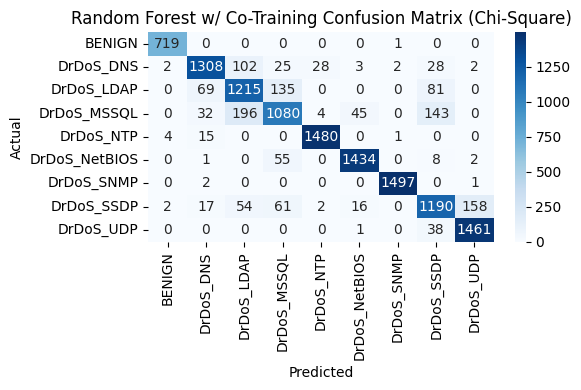

In [68]:
# === Random Forest with Co-Training ===
rf_cotrain = RandomForestClassifier(n_estimators=100, random_state=42)
rf_cotrain.fit(X_train.copy(), y_train.copy())
y_pred = rf_cotrain.predict(X_test.copy())

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})

# Output
print("\n=== RF + Co-Training ===")
print("Accuracy:", accuracy)
print(pd.DataFrame(report).transpose())
print() 

model_name = "Random Forest w/ Co-Training"  # change per model

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Decision Tree w/ Entropy-Based Uncertainty Sampling 


=== DT + Entropy Sampling ===
Accuracy: 0.8797955974842767
              precision    recall  f1-score       support
0              0.998603  0.993056  0.995822    720.000000
1              0.886792  0.877333  0.882038   1500.000000
2              0.791126  0.772667  0.781788   1500.000000
3              0.733784  0.724000  0.728859   1500.000000
4              0.977439  0.982000  0.979714   1500.000000
5              0.951058  0.958667  0.954847   1500.000000
6              0.997339  0.999333  0.998335   1500.000000
7              0.736165  0.762667  0.749181   1500.000000
8              0.907939  0.907333  0.907636   1500.000000
accuracy       0.879796  0.879796  0.879796      0.879796
macro avg      0.886694  0.886340  0.886469  12720.000000
weighted avg   0.879831  0.879796  0.879763  12720.000000


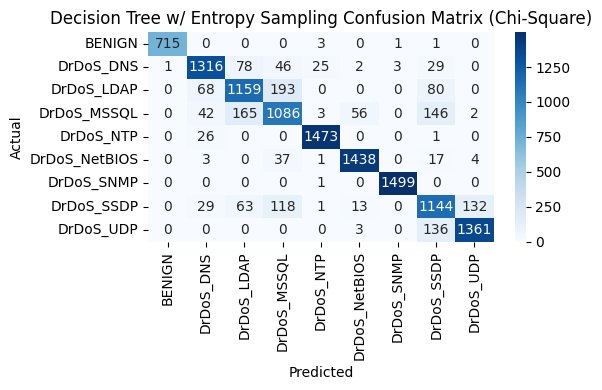

In [69]:
# === Decision Tree with Entropy-Based Sampling ===
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_entropy.fit(X_train.copy(), y_train.copy())
y_pred = dt_entropy.predict(X_test.copy())

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})

# Output
print("\n=== DT + Entropy Sampling ===")
print("Accuracy:", accuracy)
print(pd.DataFrame(report).transpose())

model_name = "Decision Tree w/ Entropy Sampling"  # change per model

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## XGBClassifier



=== XGBoost ===
Accuracy: 0.914308176100629

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       720
           1       0.94      0.89      0.91      1500
           2       0.79      0.87      0.83      1500
           3       0.87      0.74      0.80      1500
           4       0.99      0.99      0.99      1500
           5       0.99      0.96      0.97      1500
           6       1.00      1.00      1.00      1500
           7       0.80      0.84      0.82      1500
           8       0.91      0.98      0.95      1500

    accuracy                           0.91     12720
   macro avg       0.92      0.92      0.92     12720
weighted avg       0.92      0.91      0.91     12720



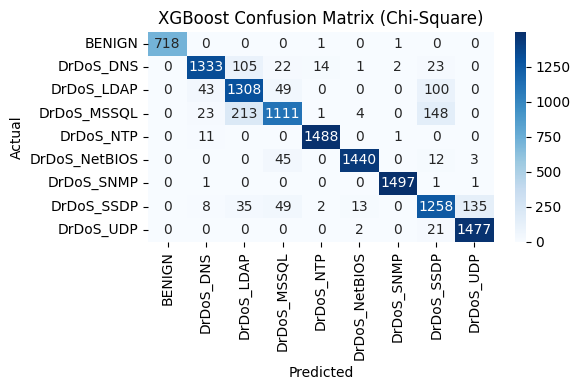

In [70]:
from xgboost import XGBClassifier
# =============== XGBOOST ===============
xgb = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb.fit(X_train, y_train.copy())
y_pred = xgb.predict(X_test)

model_name = "XGBoost"  # change per model

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

# Append metrics for each attack type and overall results
for label, metrics in report.items():
    if label.isdigit():
        model_results.append({
            "Feature Method": feature_selection_name,
            "Model": model_name,
            "Attack Type": label_encoder.inverse_transform([int(label)])[0],
            "F1-Score": metrics["f1-score"],
            "Accuracy": accuracy,  # Appending Accuracy
            "F1-Weighted": metrics["f1-score"],  # You may modify this as needed
            "Precision": metrics["precision"],  # Precision metric
            "Recall": metrics["recall"]  # Recall metric
        })

# Also append the overall metrics
model_results.append({
    "Feature Method": feature_selection_name,
    "Model": model_name,
    "Attack Type": "Overall",
    "F1-Score": report['weighted avg']['f1-score'],
    "Accuracy": accuracy,
    "F1-Weighted": report['weighted avg']['f1-score'],
    "Precision": report['weighted avg']['precision'],
    "Recall": report['weighted avg']['recall']
})

print("\n=== XGBoost ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Classification Report:\n", classification_report(y_test, y_pred))


# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f"{model_name} Confusion Matrix ({feature_selection_name})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Chart Results

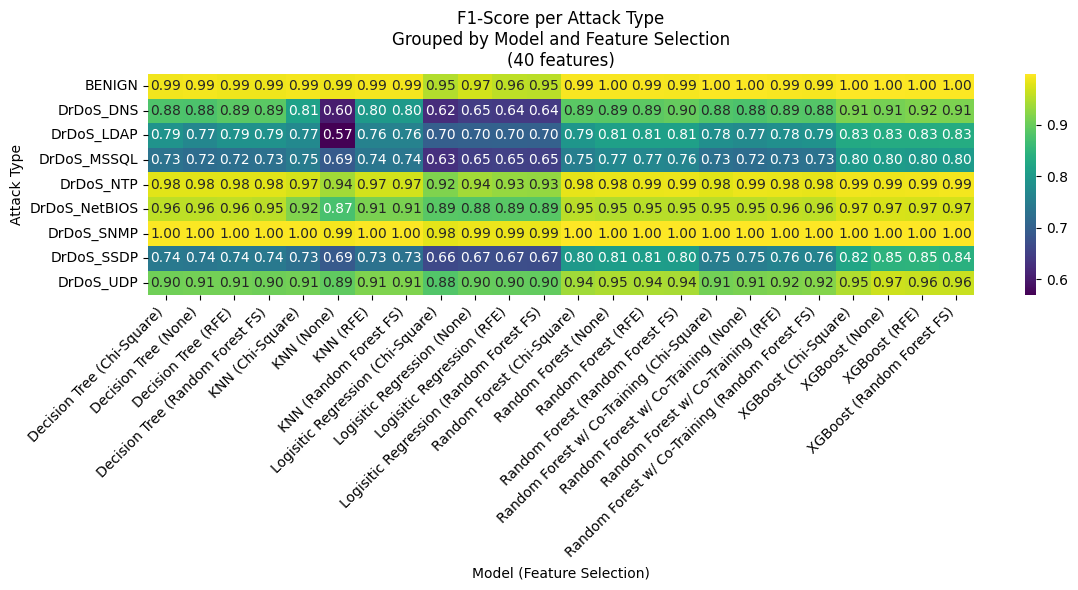

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Convert model_results to DataFrame ---
df = pd.DataFrame(model_results)
df.fillna(0, inplace=True)  # Fill any NaNs

# --- Optional: Save table as CSV ---
df.to_csv('/mnt/data/final_model_comparison.csv', index=False)

# --- Filter out "Overall" if only attack type analysis desired ---
df_filtered = df[df['Attack Type'] != "Overall"]

# --- Pivot to shape data for heatmap (Model + FS vs Attack Type) ---
df_filtered['Model_FS'] = df_filtered['Model'] + " (" + df_filtered['Feature Method'] + ")"

pivot_table = df_filtered.pivot_table(
    index='Attack Type',
    columns='Model_FS',
    values='F1-Score'
)

# --- Plot heatmap ---
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
plt.title("F1-Score per Attack Type\nGrouped by Model and Feature Selection\n(40 features)")
plt.ylabel("Attack Type")
plt.xlabel("Model (Feature Selection)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [72]:
warnings.filterwarnings("ignore")

df = pd.DataFrame(model_results)
print(df.columns)

df.fillna(0, inplace=True)  # Replace NaN with 0


# Optional: View the DataFrame to verify it's populated correctly
print(df.head())


Index(['Feature Method', 'Model', 'Attack Type', 'F1-Score', 'Accuracy',
       'F1-Weighted', 'Precision', 'Recall'],
      dtype='object')
  Feature Method Model  Attack Type  F1-Score  Accuracy  F1-Weighted  \
0           None   KNN       BENIGN  0.987569  0.791509     0.987569   
1           None   KNN    DrDoS_DNS  0.602410  0.791509     0.602410   
2           None   KNN   DrDoS_LDAP  0.568744  0.791509     0.568744   
3           None   KNN  DrDoS_MSSQL  0.689583  0.791509     0.689583   
4           None   KNN    DrDoS_NTP  0.939212  0.791509     0.939212   

   Precision    Recall  
0   0.982143  0.993056  
1   0.574365  0.633333  
2   0.536326  0.605333  
3   0.719565  0.662000  
4   0.941098  0.937333  


In [73]:
import os

# Check if the directory exists, if not, create it
save_dir = '/mnt/data'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)


Your bar plot is ready for download: [Download the chart](sandbox:/mnt/data/feature_selection_attack_comparison.png)


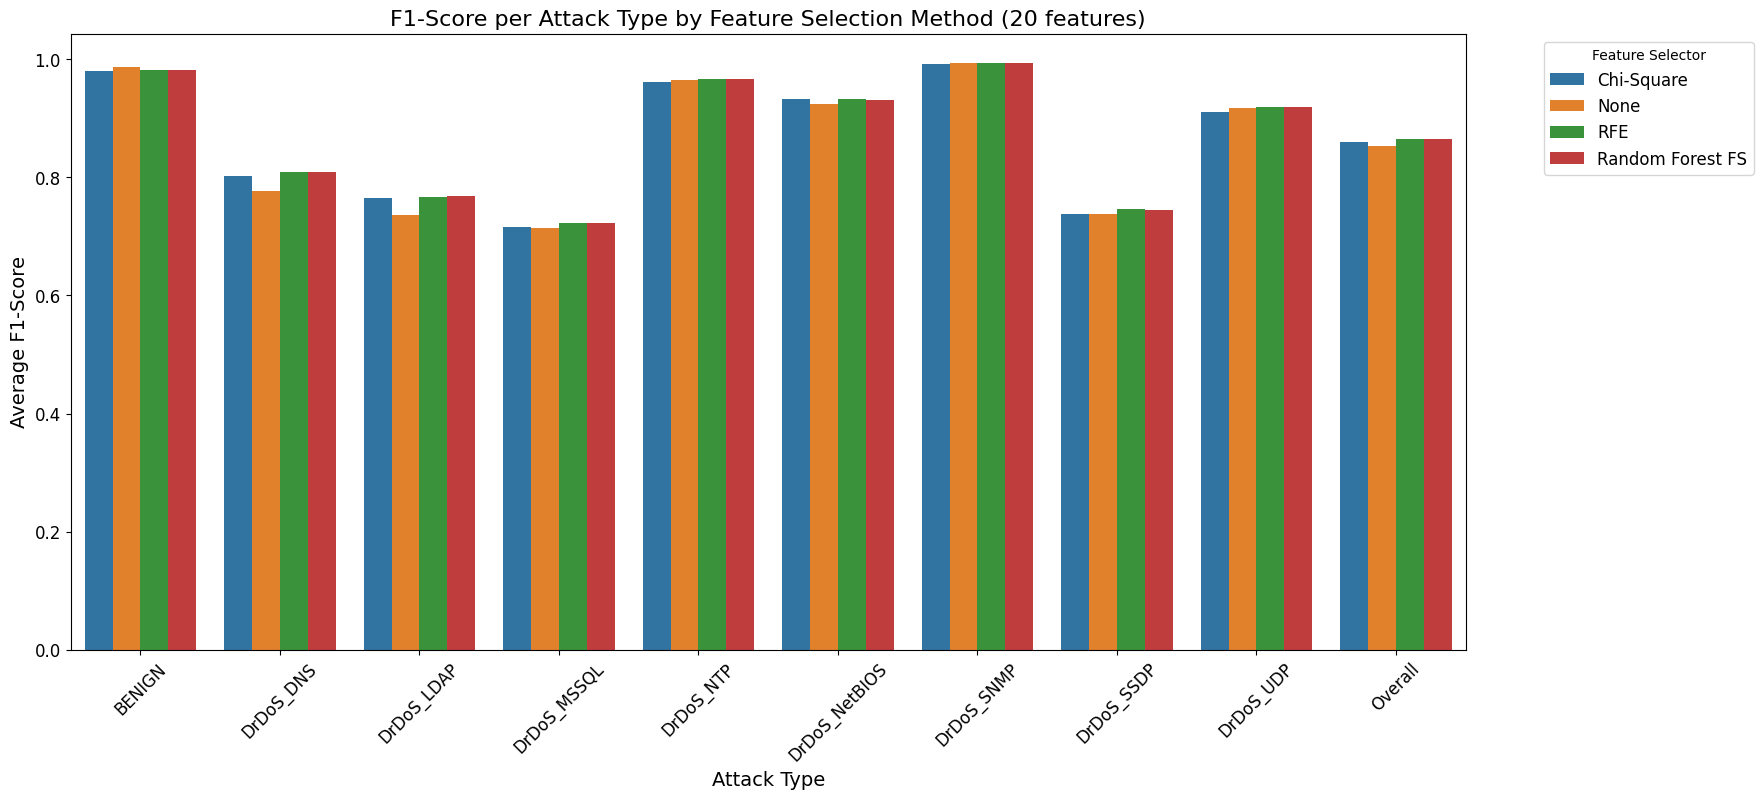

In [74]:
# Assuming model_results has been populated correctly
df = pd.DataFrame(model_results)

# Ensure no NaN values for plotting (F1-Score)
df.fillna(0, inplace=True)

# Filter the DataFrame to only include the rows with attack types (not the overall rows)
df_attack = df[df["Attack Type"].notna()]

# Group by Feature Method and Attack Type, then calculate the average F1-Score
avg_f1 = df_attack.groupby(["Feature Method", "Attack Type"])["F1-Score"].mean().reset_index()

# Create a bar plot comparing the F1-Score for each feature selection method across attack types
plt.figure(figsize=(18, 8))  # Increase figure size for better clarity
sns.barplot(data=avg_f1, x="Attack Type", y="F1-Score", hue="Feature Method", ci=None, palette="tab10")

# Customize appearance
plt.title("F1-Score per Attack Type by Feature Selection Method (20 features)", fontsize=16)
plt.ylabel("Average F1-Score", fontsize=14)
plt.xlabel("Attack Type", fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Feature Selector", fontsize=12, bbox_to_anchor=(1.05, 1), loc='upper left')

# Ensure the directory exists for saving
save_dir = '/mnt/data'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# Save the plot as a PNG file
plt.savefig(f"{save_dir}/feature_selection_attack_comparison.png", dpi=300)

# Provide a download link
print(f"Your bar plot is ready for download: [Download the chart](sandbox:/mnt/data/feature_selection_attack_comparison.png)")

# Show the plot
plt.show()


Your line plot is ready for download: [Download the chart](sandbox:/mnt/data/feature_selection_attack_comparison_line.png)


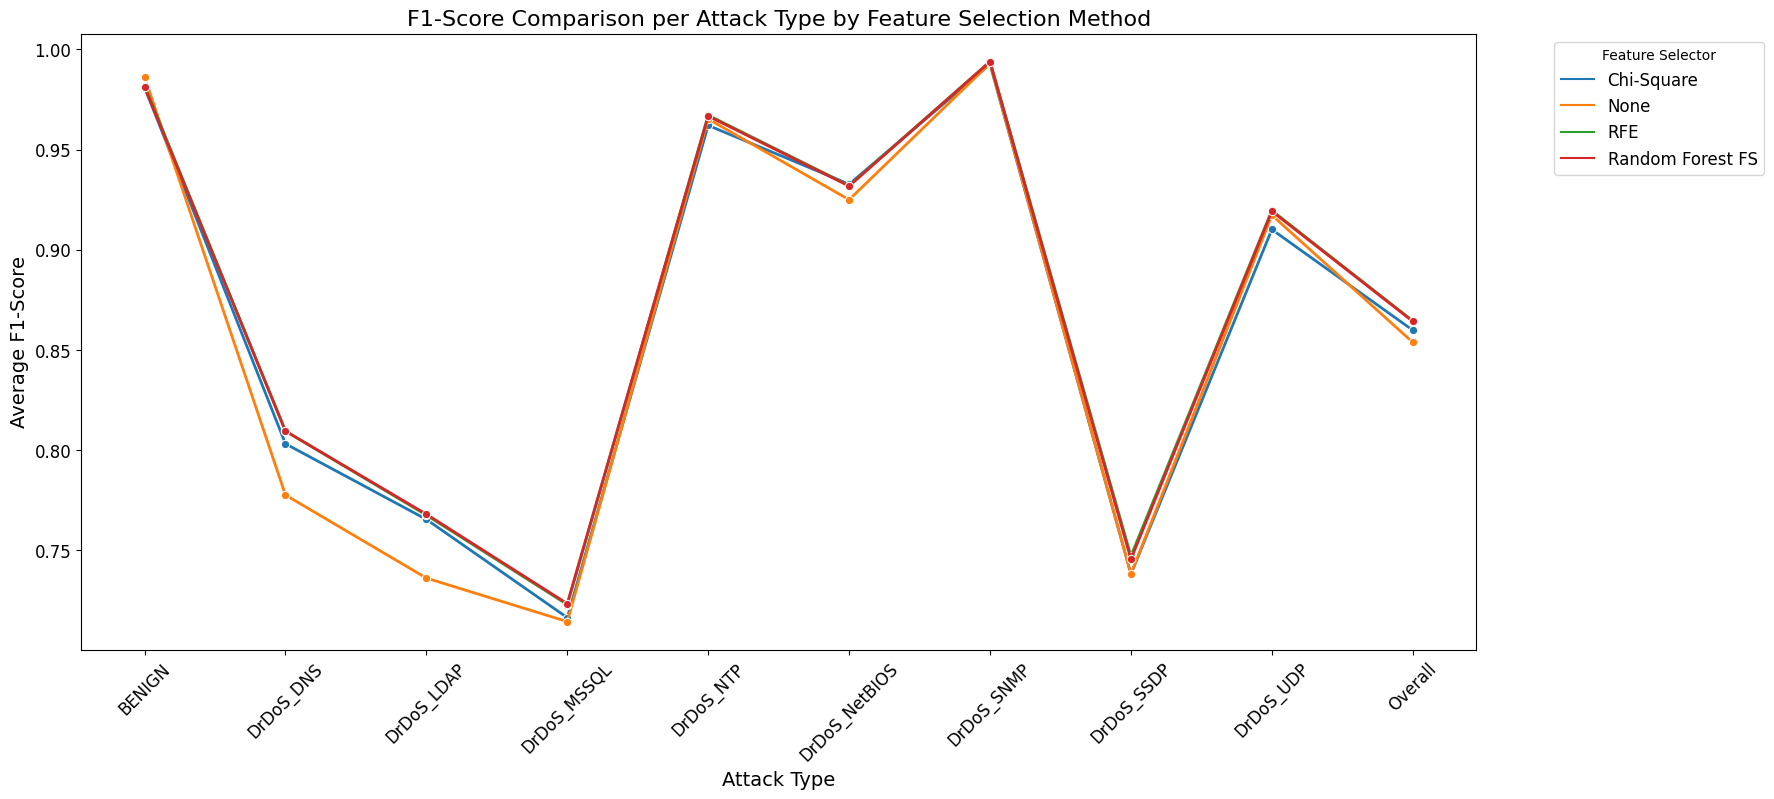

In [75]:
# Assuming model_results has been populated correctly
df = pd.DataFrame(model_results)

# Ensure no NaN values for plotting (F1-Score)
df.fillna(0, inplace=True)

# Filter the DataFrame to only include the rows with attack types (not the overall rows)
df_attack = df[df["Attack Type"].notna()]

# Group by Feature Method and Attack Type, then calculate the average F1-Score
avg_f1 = df_attack.groupby(["Feature Method", "Attack Type"])["F1-Score"].mean().reset_index()

# Create a line plot comparing the F1-Score for each feature selection method across attack types
plt.figure(figsize=(18, 8))  # Increase figure size for better clarity

# Create the line plot with seaborn
sns.lineplot(data=avg_f1, x="Attack Type", y="F1-Score", hue="Feature Method", marker='o', linewidth=2)

# Customize appearance
plt.title("F1-Score Comparison per Attack Type by Feature Selection Method", fontsize=16)
plt.ylabel("Average F1-Score", fontsize=14)
plt.xlabel("Attack Type", fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Feature Selector", fontsize=12, bbox_to_anchor=(1.05, 1), loc='upper left')

# Ensure the directory exists for saving
save_dir = '/mnt/data'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# Save the plot as a PNG file
plt.savefig(f"{save_dir}/feature_selection_attack_comparison_line.png", dpi=300)

# Provide a download link
print(f"Your line plot is ready for download: [Download the chart](sandbox:/mnt/data/feature_selection_attack_comparison_line.png)")

# Show the plot
plt.show()
